# Score de propension au don

**Question métier** : quelle est la probabilité qu'un contact de l'association fasse au moins un don l'année N ?

- **Entité** : un contact (73 124 contacts)
- **Événement** : au moins un don en N
- **Horizon** : l'année N, prédite uniquement à partir des années N-11 à N-1

Démarche en 6 étapes : données, discrétisation, sélection de variables, échantillons, corrélations, modèle, évaluation.
Le contexte, la synthèse des résultats et les recommandations métier sont présentés dans le [README](README.md).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from optbinning import OptimalBinning
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
SEED = 42

## Étape 0 : comprendre, contrôler et nettoyer les données

In [2]:
df = pd.read_csv("donnees_score.csv", sep=";", encoding="latin-1")
print(df.shape)
df.head()

(73124, 42)


,identifiant_personne,nb_don_annee_N_moins_11,nb_don_annee_N_moins_10,nb_don_annee_N_moins_09,nb_don_annee_N_moins_08,nb_don_annee_N_moins_07,nb_don_annee_N_moins_06,nb_don_annee_N_moins_05,nb_don_annee_N_moins_04,nb_don_annee_N_moins_03,...,Civilite,age,origine,abonnement,top_telephone_renseigne,top_portable_renseigne,top_membre,top_adresse_email_FAI,top_email_avec_nom,top_email_avec_prenom
0,1,0,0,0,0,0,0,1,0,0,...,Madame,Non renseigné,BDD,Pas d'abonnement,1,0,0,0,0,1
1,2,0,0,0,0,0,0,0,0,0,...,Monsieur,55_65_ans,Web actif,Newsletter spécifique,1,1,0,1,1,1
2,3,0,0,0,0,0,0,0,0,0,...,Madame,Non renseigné,BDD,Pas d'abonnement,0,0,0,1,1,1
3,4,0,0,0,0,0,0,0,0,0,...,Madame,45_55_ans,Web,Newsletter générale,0,0,0,1,0,1
4,5,0,0,0,0,0,0,0,0,0,...,Monsieur,Non renseigné,BDD,Pas d'abonnement,1,0,0,1,1,0


### Contrôle qualité

In [3]:
nb = [c for c in df if c.startswith("nb_don_annee_N_moins")]
mo = [c for c in df if c.startswith("Montant_Don_N_moins")]

print("Doublons d'identifiant :", df["identifiant_personne"].duplicated().sum())
print("Valeurs vides          :", df.isna().sum().sum())
print("Montants négatifs      :", (df[mo + ["Montant_Don_N"]] < 0).sum().sum())
print(f"Âge non renseigné      : {(df['age'] == 'Non renseigné').mean():.1%}")

dons = df[mo].stack()
dons = dons[dons > 0]
print("\nMontant d'un don (années N-11 à N-1) :")
print(dons.describe(percentiles=[.01, .5, .99]).round(0))

Doublons d'identifiant : 0
Valeurs vides          : 0
Montants négatifs      : 0
Âge non renseigné      : 63.3%

Montant d'un don (années N-11 à N-1) :
count   117,009.000
mean         61.000
std          97.000
min           1.000
1%           10.000
50%          50.000
99%         300.000
max      10,000.000
dtype: float64


**Décisions** :
- capping P1/P99 des montants de don, pour que les valeurs extrêmes ne « tirent » pas le modèle ;
- « Âge non renseigné » est gardé comme une modalité à part entière ;
- la modalité « Autre » de l'origine (très peu de contacts) est regroupée avec « BDD » ;
- `TR_age_65_75_ans` (valeurs de 0 à 12, sens peu clair) n'est pas utilisée ;
- `nb_don_annee_N` et `Montant_Don_N` sont la réponse : jamais utilisées comme variables explicatives.

In [4]:
p1, p99 = dons.quantile([0.01, 0.99])
for c in mo:
    df[c] = df[c].where(df[c] == 0, df[c].clip(p1, p99))
print(f"Montants d'un don ramenés entre {p1:.0f} € et {p99:.0f} €")

df["origine"] = df["origine"].replace({"Autre": "BDD"})

Montants d'un don ramenés entre 10 € et 300 €


### La cible et les indicateurs (calculés uniquement sur le passé, N-11 à N-1)

In [5]:
df["cible"] = (df["nb_don_annee_N"] > 0).astype(int)
print(f"Taux de donateurs en N : {df['cible'].mean():.1%}")

df["nb_dons_total"] = df[nb].sum(axis=1)
df["nb_annees_avec_don"] = (df[nb] > 0).sum(axis=1)
df["montant_total"] = df[mo].sum(axis=1)
df["montant_moyen"] = (df["montant_total"] / df["nb_dons_total"].replace(0, np.nan)).fillna(0)
df["montant_max"] = df[mo].max(axis=1)

# Récence : années depuis le dernier don (1 = don en N-1, 12 = jamais donné)
a_donne = df[nb[::-1]].to_numpy() > 0
df["recence"] = np.where(a_donne.any(axis=1), a_donne.argmax(axis=1) + 1, 12)

# Ancienneté : années depuis le premier don (0 = jamais donné)
a_donne = df[nb].to_numpy() > 0
df["anciennete"] = np.where(a_donne.any(axis=1), 11 - a_donne.argmax(axis=1), 0)

canaux = df[["NB_don_par_Telephone", "NB_don_par__INTERNET", "NB_don_par_Autre_Canal"]].sum(axis=1)
paiements = df[["NB_paiement_CB", "NB_paiement_CHEQUE", "NB_paiement_AUTRE"]].sum(axis=1)
df["pct_internet"] = (df["NB_don_par__INTERNET"] / canaux.replace(0, np.nan)).fillna(0)
df["pct_telephone"] = (df["NB_don_par_Telephone"] / canaux.replace(0, np.nan)).fillna(0)
df["pct_cb"] = (df["NB_paiement_CB"] / paiements.replace(0, np.nan)).fillna(0)

# Premier réflexe : les indicateurs racontent-ils quelque chose ?
print(f"Ont donné en N-1 : {df.loc[df.recence == 1, 'cible'].mean():.1%} redonnent en N")
print(f"Les autres       : {df.loc[df.recence > 1, 'cible'].mean():.1%}")

Taux de donateurs en N : 25.6%
Ont donné en N-1 : 39.4% redonnent en N
Les autres       : 19.0%


## Étape 3 (faite en premier) : échantillons d'apprentissage et de test

Le découpage 70/30 est fait **avant** la discrétisation : les tranches sont apprises sur l'échantillon d'apprentissage
seulement, puis appliquées telles quelles au test. Sinon le modèle « verrait » le test et la note serait truquée.
Le tirage est stratifié sur la cible.

In [6]:
train, test = train_test_split(df, test_size=0.30, stratify=df["cible"], random_state=SEED)
pd.DataFrame({
    "Contacts": [len(train), len(test)],
    "Taux de donateurs": [train["cible"].mean(), test["cible"].mean()],
}, index=["Apprentissage (70 %)", "Test (30 %)"])

,Contacts,Taux de donateurs
Apprentissage (70 %),51186,0.256
Test (30 %),21938,0.256


## Étape 1 : la discrétisation, cœur de la démarche

Découpage par arbre de décision avec `optbinning` : au plus 6 tranches, au moins 2 % des contacts par tranche,
tendance monotone pour les variables numériques. Pour les variables texte, les modalités au comportement proche sont regroupées.

Convention : **WoE positif = tranche plus donatrice que la moyenne** (optbinning calcule l'inverse, on change donc le signe).

In [7]:
numeriques = ["recence", "anciennete", "montant_total", "montant_moyen", "montant_max",
              "nb_dons_total", "nb_annees_avec_don", "NB_paiement_CB", "NB_don_par__INTERNET",
              "NB_don_par_Telephone", "NB_paiement_CHEQUE", "pct_internet", "pct_telephone", "pct_cb",
              "top_portable_renseigne", "top_telephone_renseigne", "top_adresse_email_FAI", "top_membre"]
categorielles = ["origine", "abonnement", "age"]

binnings = {}
for var in numeriques + categorielles:
    cat = var in categorielles
    ob = OptimalBinning(name=var, dtype="categorical" if cat else "numerical",
                        max_n_bins=6, min_bin_size=0.02,
                        monotonic_trend=None if cat else "auto_asc_desc")
    ob.fit(train[var].values, train["cible"].values)
    binnings[var] = ob

def woe(data, var):
    return -binnings[var].transform(data[var].values, metric="woe")

def table_tranches(var):
    t = binnings[var].binning_table.build()
    t = t[~t.index.isin(["Totals"])]
    t = t[t["Count"] > 0][["Bin", "Count (%)", "Event rate", "WoE"]].copy()
    t["WoE"] = -t["WoE"].astype(float)
    return t.rename(columns={"Bin": "Tranche", "Count (%)": "% base", "Event rate": "Taux de don"})

table_tranches("recence")

,Tranche,% base,Taux de don,WoE
0,"(-inf, 6.50)",0.868,0.210,-0.260
1,"[6.50, inf)",0.132,0.560,1.308


In [8]:
for var in ["abonnement", "origine", "age", "montant_total"]:
    print(var)
    display(table_tranches(var))

abonnement


,Tranche,% base,Taux de don,WoE
0,[Pas d'abonnement],0.266,0.046,-1.968
1,[Newsletter spécifique],0.312,0.072,-1.497
2,[Newsletter générale],0.422,0.525,1.167


origine


,Tranche,% base,Taux de don,WoE
0,[BDD],0.455,0.029,-2.445
1,[Web actif],0.054,0.298,0.212
2,"[Web, Bénévole]",0.491,0.462,0.914


age


,Tranche,% base,Taux de don,WoE
0,[Non renseigné],0.631,0.092,-1.225
1,"[Moins de 18 ans, 35_45_ans]",0.069,0.495,1.048
2,[25_35_ans],0.050,0.520,1.146
3,"[45_55_ans, 18_25_ans]",0.097,0.521,1.153
4,"[Plus_75_ans, 65_75_ans]",0.059,0.567,1.335
5,[55_65_ans],0.094,0.575,1.368


montant_total


,Tranche,% base,Taux de don,WoE
0,"(-inf, 15.12)",0.141,0.518,1.138
1,"[15.12, inf)",0.859,0.213,-0.240


## Étape 2 : les variables les plus discriminantes

- **IV** (Information Value) : force du lien avec la cible.
- **Khi-carré** : le lien n'est-il pas dû au hasard ? Avec 51 000 contacts presque tout est significatif,
  on regarde donc aussi le **V de Cramér** (force du lien, de 0 à 1).

Règle retenue : IV ≥ 0,02 et p-value < 0,05.

In [9]:
lignes = []
for var, ob in binnings.items():
    tranches = ob.transform(train[var].values, metric="indices")
    tab = pd.crosstab(tranches, train["cible"])
    chi2, p, _, _ = chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    iv = ob.binning_table.build().loc["Totals", "IV"]
    lignes.append({"Variable": var, "IV": iv, "V de Cramér": v, "p-value": p})

selection = pd.DataFrame(lignes).sort_values("IV", ascending=False).reset_index(drop=True)
selection["Retenue"] = (selection["IV"] >= 0.02) & (selection["p-value"] < 0.05)
selection

,Variable,IV,V de Cramér,p-value,Retenue
0,origine,1.814,0.483,0.000,True
1,abonnement,1.726,0.527,0.000,True
2,age,1.336,0.494,0.000,True
3,montant_moyen,0.395,0.298,0.000,True
4,recence,0.331,0.272,0.000,True
5,anciennete,0.310,0.259,0.000,True
6,pct_cb,0.297,0.241,0.000,True
7,montant_total,0.268,0.243,0.000,True
8,pct_internet,0.260,0.224,0.000,True
9,top_portable_renseigne,0.256,0.236,0.000,True


## Étape 4 : les corrélations entre indicateurs

Deux indicateurs très corrélés racontent la même histoire et rendent les coefficients instables.
Pour chaque paire corrélée à plus de 0,7 (corrélation calculée sur les WoE), on garde la variable à la plus forte IV.

In [10]:
retenues = selection.loc[selection["Retenue"], "Variable"].tolist()
X_woe = pd.DataFrame({v: woe(train, v) for v in retenues}, index=train.index)
corr = X_woe.corr()

paires = [(a, b, corr.loc[a, b]) for i, a in enumerate(retenues) for b in retenues[i + 1:]
          if abs(corr.loc[a, b]) > 0.7]
pd.DataFrame(paires, columns=["Variable 1", "Variable 2", "Corrélation"]).sort_values("Corrélation", ascending=False)

,Variable 1,Variable 2,Corrélation
7,nb_annees_avec_don,nb_dons_total,0.979
2,montant_total,montant_max,0.956
4,NB_paiement_CB,NB_don_par__INTERNET,0.896
1,montant_moyen,montant_max,0.856
0,montant_moyen,montant_total,0.832
5,NB_paiement_CB,nb_dons_total,0.782
3,NB_paiement_CB,nb_annees_avec_don,0.778
8,NB_don_par__INTERNET,nb_dons_total,0.770
6,nb_annees_avec_don,NB_don_par__INTERNET,0.754


In [11]:
# Variables écartées pour redondance (la plus faible IV de chaque paire, ou information déjà portée ailleurs)
redondantes = ["montant_moyen", "montant_max", "nb_dons_total", "nb_annees_avec_don", "NB_don_par__INTERNET"]
candidates = [v for v in retenues if v not in redondantes]
candidates

['origine',
 'abonnement',
 'age',
 'recence',
 'anciennete',
 'pct_cb',
 'montant_total',
 'pct_internet',
 'top_portable_renseigne',
 'NB_paiement_CB',
 'pct_telephone',
 'top_telephone_renseigne',
 'top_adresse_email_FAI']

## Étape 5 : le modèle, une régression logistique sur variables discrétisées

$$\text{logit}(p) = \text{constante} + \sum_i \text{coef}_i \times \text{WoE}_i \qquad p = \frac{1}{1 + e^{-\text{logit}}}$$

Chaque coefficient doit être **positif** (un WoE élevé doit augmenter la probabilité de don) et **significatif** (p < 0,05).
On retire une à une les variables qui ne respectent pas ces deux règles.

In [12]:
X_train = pd.DataFrame({v: woe(train, v) for v in candidates}, index=train.index)
X_test = pd.DataFrame({v: woe(test, v) for v in candidates}, index=test.index)
y_train, y_test = train["cible"], test["cible"]

variables = list(candidates)
while True:
    modele = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
    coefs, pvals = modele.params.drop("const"), modele.pvalues.drop("const")
    a_retirer = coefs[(coefs <= 0) | (pvals >= 0.05)]
    if a_retirer.empty:
        break
    pire = a_retirer.abs().idxmin() if (coefs <= 0).sum() == 0 else coefs.idxmin()
    print(f"Retirée : {pire} (coef {coefs[pire]:+.3f}, p = {pvals[pire]:.3f})")
    variables.remove(pire)

print(f"\nModèle final : {len(variables)} variables")

Retirée : pct_cb (coef -0.025, p = 0.525)
Retirée : top_telephone_renseigne (coef +0.002, p = 0.970)

Modèle final : 11 variables


In [13]:
poids = pd.DataFrame({"Coefficient": modele.params.drop("const"),
                      "p-value": modele.pvalues.drop("const")})
poids["IV"] = selection.set_index("Variable").loc[poids.index, "IV"]
print(f"Constante : {modele.params['const']:+.3f}")
poids.sort_values("Coefficient", ascending=False)

Constante : -1.045


,Coefficient,p-value,IV
recence,1.004,0.000,0.331
NB_paiement_CB,0.908,0.000,0.228
pct_internet,0.902,0.000,0.260
abonnement,0.888,0.000,1.726
age,0.777,0.000,1.336
montant_total,0.732,0.000,0.268
top_adresse_email_FAI,0.638,0.000,0.023
pct_telephone,0.624,0.000,0.129
anciennete,0.578,0.000,0.310
origine,0.137,0.000,1.814


## Étape 6 : la qualité du score sur l'échantillon de test

In [14]:
score_train = modele.predict(sm.add_constant(X_train[variables]))
score_test = modele.predict(sm.add_constant(X_test[variables]))

def ks(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return (tpr - fpr).max()

auc_train, auc_test = roc_auc_score(y_train, score_train), roc_auc_score(y_test, score_test)
pd.DataFrame({
    "Apprentissage": [auc_train, 2 * auc_train - 1, ks(y_train, score_train)],
    "Test": [auc_test, 2 * auc_test - 1, ks(y_test, score_test)],
}, index=["AUC", "Gini", "KS"])

,Apprentissage,Test
AUC,0.921,0.925
Gini,0.842,0.851
KS,0.722,0.727


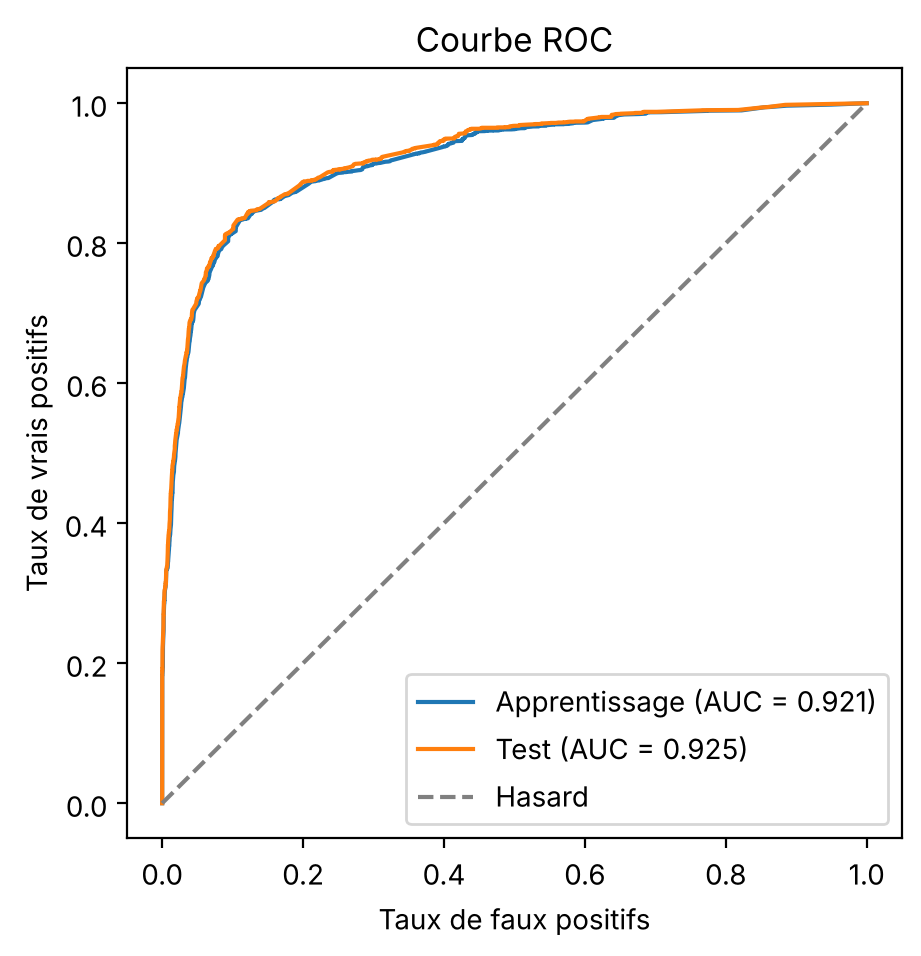

In [15]:
fig, ax = plt.subplots(figsize=(5, 5))
for nom, y, s in [("Apprentissage", y_train, score_train), ("Test", y_test, score_test)]:
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y, s):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Hasard")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbe ROC")
ax.legend()
plt.show()

### Matrice de confusion (seuil de 0,5)

In [16]:
pred = (score_test >= 0.5).astype(int)
mc = confusion_matrix(y_test, pred)
display(pd.DataFrame(mc, index=["Réellement non-donateur", "Réellement donateur"],
                     columns=["Prédit non-donateur", "Prédit donateur"]))
tn, fp, fn, tp = mc.ravel()
print(f"Exactitude : {(tp + tn) / mc.sum():.1%}")
print(f"Précision  : {tp / (tp + fp):.1%}")
print(f"Rappel     : {tp / (tp + fn):.1%}")

,Prédit non-donateur,Prédit donateur
Réellement non-donateur,15441,880
Réellement donateur,1506,4111


Exactitude : 89.1%
Précision  : 82.4%
Rappel     : 73.2%


### Analyse par décile

In [17]:
res = pd.DataFrame({"cible": y_test, "score": score_test})
res["decile"] = pd.qcut(res["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
deciles = res.groupby("decile", observed=True).agg(Contacts=("cible", "size"), Donateurs=("cible", "sum"))
deciles["Taux de don"] = deciles["Donateurs"] / deciles["Contacts"]
deciles["Lift"] = deciles["Taux de don"] / res["cible"].mean()
deciles["Donateurs captés (cumul)"] = deciles["Donateurs"].cumsum() / deciles["Donateurs"].sum()
deciles

,Contacts,Donateurs,Taux de don,Lift,Donateurs captés (cumul)
decile,,,,,
1,2194,2062,0.940,3.671,0.367
2,2194,1714,0.781,3.051,0.672
3,2194,919,0.419,1.636,0.836
4,2193,344,0.157,0.613,0.897
5,2194,197,0.090,0.351,0.932
6,2194,184,0.084,0.328,0.965
7,2193,71,0.032,0.126,0.978
8,2194,63,0.029,0.112,0.989
9,2194,39,0.018,0.069,0.996


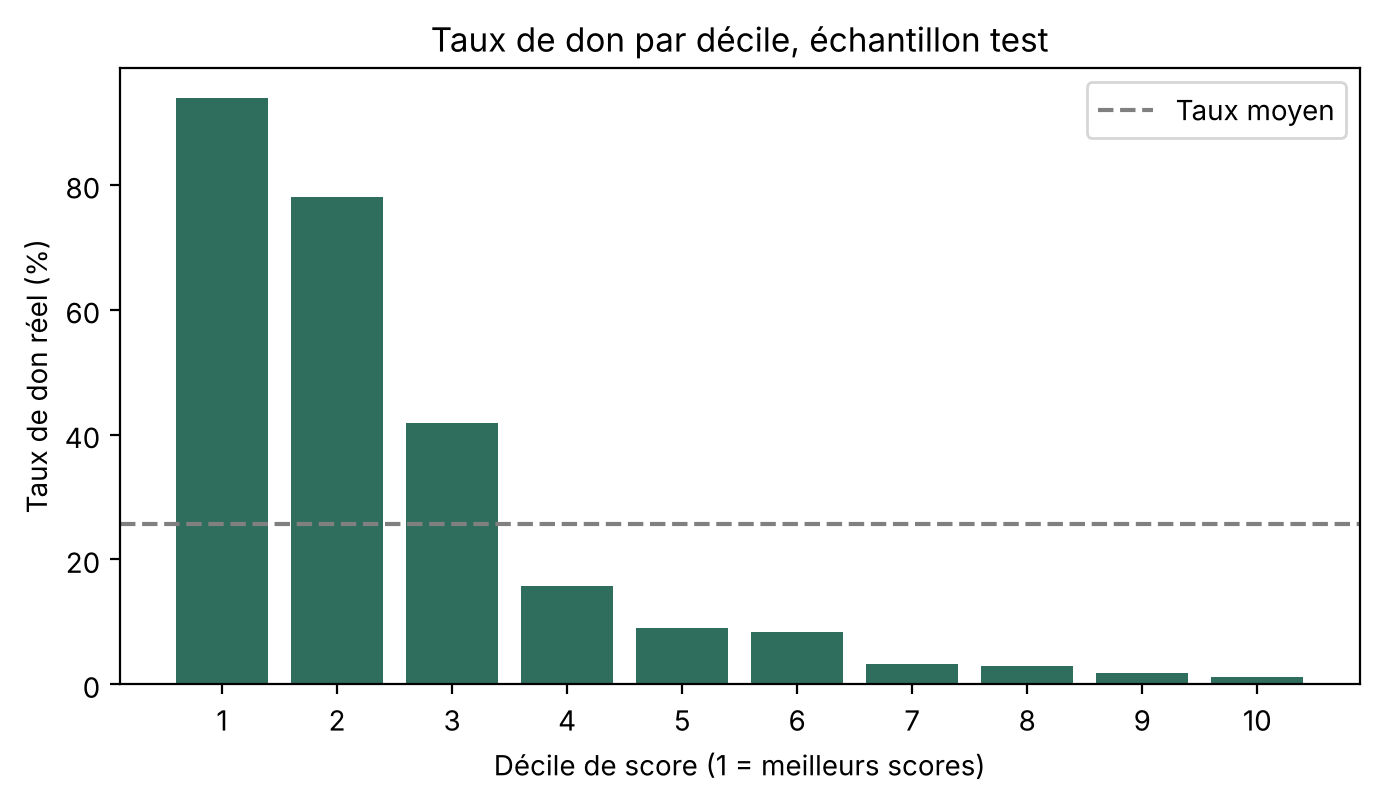

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(deciles.index.astype(str), deciles["Taux de don"] * 100, color="#2F6E5D")
ax.axhline(res["cible"].mean() * 100, color="grey", linestyle="--", label="Taux moyen")
ax.set_xlabel("Décile de score (1 = meilleurs scores)")
ax.set_ylabel("Taux de don réel (%)")
ax.set_title("Taux de don par décile, échantillon test")
ax.legend()
plt.show()

## Point de vigilance : les contacts sans historique de don

Une partie des contacts n'a aucun don avant N, et ils ont tous donné en N : ils ont probablement été ajoutés à la base
*parce qu'*ils ont donné. Test de sensibilité : la performance sur les seuls contacts avec historique.

In [19]:
sans_histo = df["nb_dons_total"] == 0
print(f"Contacts sans historique : {sans_histo.sum():,} ({sans_histo.mean():.1%}), "
      f"taux de don en N : {df.loc[sans_histo, 'cible'].mean():.0%}")

avec = test["nb_dons_total"] > 0
print(f"AUC sur le test, contacts avec historique (modèle initial) : "
      f"{roc_auc_score(y_test[avec], score_test[avec]):.3f}")

tr_avec = train["nb_dons_total"] > 0
modele_h = sm.Logit(y_train[tr_avec], sm.add_constant(X_train.loc[tr_avec, variables])).fit(disp=0)
score_h = modele_h.predict(sm.add_constant(X_test.loc[avec, variables]))
print(f"AUC sur le test, contacts avec historique (ré-entraîné)    : {roc_auc_score(y_test[avec], score_h):.3f}")

Contacts sans historique : 5,084 (7.0%), taux de don en N : 100%
AUC sur le test, contacts avec historique (modèle initial) : 0.900


AUC sur le test, contacts avec historique (ré-entraîné)    : 0.913


## Conclusion

- Le score classe très bien les contacts et reste stable entre apprentissage et test.
- Cibler les déciles 1 à 3 (30 % de la base) permet de toucher la grande majorité des donateurs.
- Avant tout usage opérationnel : vérifier avec l'association que l'abonnement et l'origine ne sont pas enregistrés
  après le don de l'année N (risque de fuite d'information).

Recommandations métier et limites : voir le [README](README.md).